In [ ]:
!pip install tensorflow

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, Dropout
from tensorflow.keras.utils import to_categorical

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
!pip install kaggle

In [ ]:
#importing dataset
import os
os.environ['KAGGLE_USERNAME'] = "your_username_here"
os.environ['KAGGLE_KEY'] = "your_long_api_key_here"

!kaggle datasets download -d meruvulikith/190k-spam-ham-email-dataset-for-classification
!unzip 190k-spam-ham-email-dataset-for-classification.zip

Dataset URL: https://www.kaggle.com/datasets/meruvulikith/190k-spam-ham-email-dataset-for-classification
License(s): MIT
100% 107M/107M [00:01<00:00, 106MB/s]

Archive:  190k-spam-ham-email-dataset-for-classification.zip
  inflating: spam_Emails_data.csv    


In [ ]:
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.corpus import stopwords

# Download stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# Load dataset - using latin-1 to avoid the 'utf-8' error we saw earlier
# Ensure 'enron_emails.csv' is still in your Colab file sidebar
data = pd.read_csv('spam_Emails_data.csv', encoding='latin-1')

# Clean column names
data.columns = data.columns.str.strip().str.lower()

# Handle missing values (the cause of our previous 'float' error)
data = data.dropna(subset=['text'])

print("Step 1 Complete: Data Loaded.")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Step 1 Complete: Data Loaded.


In [ ]:
def create_3_classes(row):
    text = str(row['text']).lower()
    # Handle column names dynamically
    label = str(row.get('spam', row.get('label', '0'))).lower()

    promo_keywords = ['offer', 'discount', 'sale', 'subscribe', 'newsletter',
                      'coupon', 'promo', 'deal', 'shipping', 'limited time']

    if label == '1' or label == 'spam':
        if any(word in text for word in promo_keywords):
            return 'Promotional'
        return 'Spam'
    return 'Ham'

data['category'] = data.apply(create_3_classes, axis=1)
print(data['category'].value_counts())

category
Ham            102159
Spam            57149
Promotional     34542
Name: count, dtype: int64


In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    words = text.split()
    clean_words = [w for w in words if w not in stop_words and not w.isdigit()]
    # Remove the 'escapenumber' placeholder specific to your dataset
    return " ".join(clean_words).replace('escapenumber', '')

data['clean_text'] = data['clean_text'] = data['text'].apply(clean_text)
print("Step 3 Complete: Text Cleaned.")

Step 3 Complete: Text Cleaned.


In [ ]:
#label encoding and splitting dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Convert labels to numbers (Ham=0, Promotional=1, Spam=2)
le = LabelEncoder()
data['label_num'] = le.fit_transform(data['category'])

# 2. Define X (features) and y (target)
X = data['clean_text']
y = data['label_num']

# 3. Split: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print("Classes identified:", le.classes_)

Training samples: 155080
Testing samples: 38770
Classes identified: ['Ham' 'Promotional' 'Spam']


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Constants
max_words = 10000
max_len = 150

# Encode Labels (Ham=0, Promotional=1, Spam=2)
le = LabelEncoder()
y = le.fit_transform(data['category'])

# Split Data
X_train, X_test, y_train, y_test = train_test_split(data['clean_text'], y, test_size=0.2, random_state=42, stratify=y)

# Tokenize and Pad
tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_pad = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=max_len)
X_test_pad = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=max_len)

print("Step 4 Complete: Sequences ready for GPU.")

Step 4 Complete: Sequences ready for GPU.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

# 1. Initialize TF-IDF (ensure X_train and X_test were re-created after your data load)
tfidf = TfidfVectorizer(max_features=5000)

# 2. Re-create the numerical matrices
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# 3. Initialize and Train the Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# 4. Make Predictions
y_pred = nb_model.predict(X_test_tfidf)

# 5. Output Results
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Accuracy: 88.53%

Classification Report:

              precision    recall  f1-score   support

         Ham       0.92      0.97      0.95     20432
 Promotional       0.81      0.77      0.79      6908
        Spam       0.86      0.80      0.83     11430

    accuracy                           0.89     38770
   macro avg       0.86      0.85      0.85     38770
weighted avg       0.88      0.89      0.88     38770



In [ ]:
#using naive bayes
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

# 1. Initialize and Train
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# 2. Make Predictions
y_pred = nb_model.predict(X_test_tfidf)

# 3. See how we did!
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Accuracy: 88.53%

Classification Report:

              precision    recall  f1-score   support

         Ham       0.92      0.97      0.95     20432
 Promotional       0.81      0.77      0.79      6908
        Spam       0.86      0.80      0.83     11430

    accuracy                           0.89     38770
   macro avg       0.86      0.85      0.85     38770
weighted avg       0.88      0.89      0.88     38770



In [ ]:
#training model using LSTM
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional, Input

model = Sequential([
    Input(shape=(max_len,)),
    Embedding(input_dim=max_words, output_dim=128),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Start training
history = model.fit(X_train_pad, np.array(y_train),
                    epochs=5,
                    batch_size=64,
                    validation_data=(X_test_pad, np.array(y_test)))

Epoch 1/5
2424/2424 ━━━━━━━━━━━━━━━━━━━━ 46s 17ms/step - accuracy: 0.9332 - loss: 0.2031 - val_accuracy: 0.9645 - val_loss: 0.1084
Epoch 2/5
2424/2424 ━━━━━━━━━━━━━━━━━━━━ 40s 16ms/step - accuracy: 0.9675 - loss: 0.1086 - val_accuracy: 0.9726 - val_loss: 0.0884
Epoch 3/5
2424/2424 ━━━━━━━━━━━━━━━━━━━━ 40s 16ms/step - accuracy: 0.9790 - loss: 0.0702 - val_accuracy: 0.9751 - val_loss: 0.0825
Epoch 4/5
2424/2424 ━━━━━━━━━━━━━━━━━━━━ 40s 17ms/step - accuracy: 0.9861 - loss: 0.0473 - val_accuracy: 0.9764 - val_loss: 0.0823
Epoch 5/5
2424/2424 ━━━━━━━━━━━━━━━━━━━━ 40s 17ms/step - accuracy: 0.9903 - loss: 0.0326 - val_accuracy: 0.9768 - val_loss: 0.0853


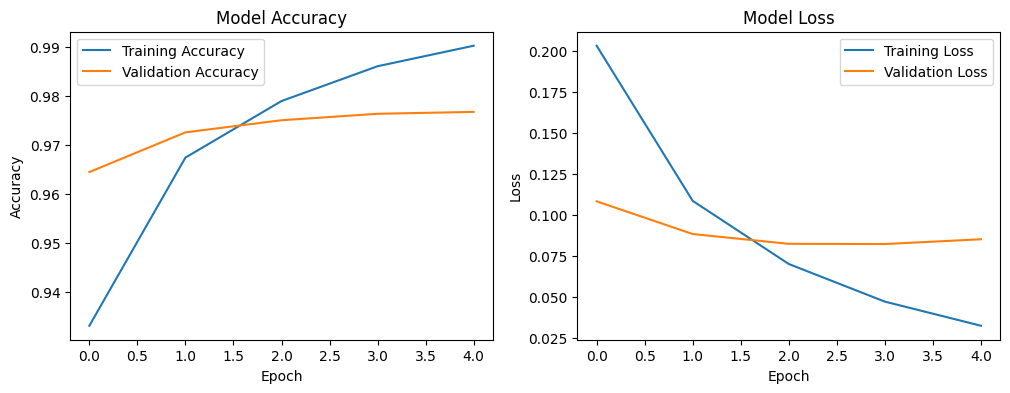

In [ ]:
#displaying accuracy in graph
import matplotlib.pyplot as plt

# Plot Accuracy
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# 1. Get model predictions (it outputs probabilities)
y_pred_probs = model.predict(X_test_pad)

# 2. Convert probabilities to class numbers (0, 1, or 2)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. Print the report
# Use le.classes_ to map numbers back to 'Ham', 'Spam', 'Promotional'
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

1212/1212 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step
Classification Report:

              precision    recall  f1-score   support

         Ham       0.99      0.98      0.99     20432
 Promotional       0.97      0.97      0.97      6908
        Spam       0.96      0.97      0.97     11430

    accuracy                           0.98     38770
   macro avg       0.97      0.97      0.97     38770
weighted avg       0.98      0.98      0.98     38770



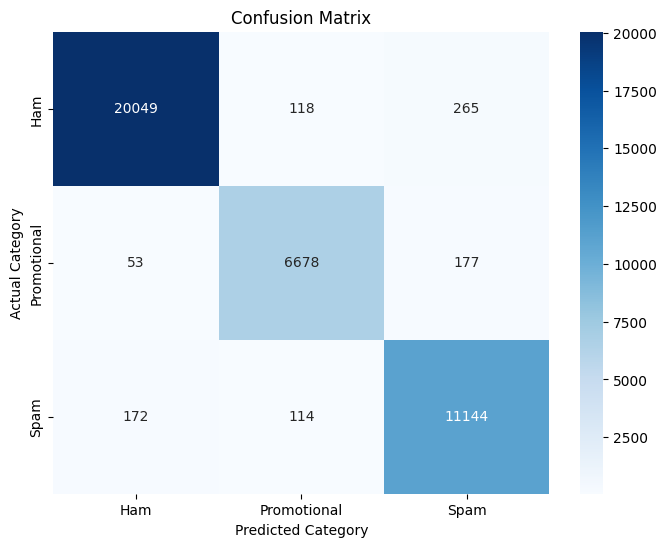

In [ ]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix')
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.show()

In [ ]:
def predict_email(sample_text):
    # 1. Clean the custom text
    cleaned = clean_text(sample_text)

    # 2. Convert to sequence and pad
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=max_len)

    # 3. Predict
    prediction = model.predict(padded, verbose=0)
    class_idx = np.argmax(prediction)

    # 4. Get the label name
    result_label = le.classes_[class_idx]
    confidence = np.max(prediction) * 100

    print(f"--- Prediction Result ---")
    print(f"Message: {sample_text[:100]}...")
    print(f"Category: {result_label}")
    print(f"Confidence: {confidence:.2f}%")

# --- Let's Test It! ---
# Test 1: A typical 'Ham' email
predict_email("Hey, are we still meeting for the project discussion at 5 PM today?")

# Test 2: A 'Promotional' email
predict_email("Final Sale! Use code SAVE50 to get 50% off on all items. Limited time offer!")

# Test 3: A 'Spam' email
predict_email("CONGRATULATIONS! You have won a $1000 gift card. Click the link to claim your reward now!")

--- Prediction Result ---
Message: Hey, are we still meeting for the project discussion at 5 PM today?...
Category: Ham
Confidence: 100.00%
--- Prediction Result ---
Message: Final Sale! Use code SAVE50 to get 50% off on all items. Limited time offer!...
Category: Promotional
Confidence: 98.64%
--- Prediction Result ---
Message: CONGRATULATIONS! You have won a $1000 gift card. Click the link to claim your reward now!...
Category: Spam
Confidence: 77.67%


In [ ]:
import gradio as gr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import PyPDF2
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.preprocessing.sequence import pad_sequences

# ================= CLASSIFICATION REPORT =================
report_dict = classification_report(
    y_test, y_pred,
    target_names=le.classes_,
    output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose().round(3)

# ================= PREDICTION FUNCTION =================
def enhanced_predict(email_text):
    if not email_text.strip():
        empty = "<div style='text-align:center; opacity:0.5;'>No Data</div>"
        return empty, empty, empty, 0

    cleaned = clean_text(email_text)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=150)

    prediction = model.predict(padded, verbose=0)[0]
    idx = np.argmax(prediction)
    conf = round(float(prediction[idx]) * 100, 2)

    def get_card(title, icon, color, is_active, confidence):
        return f"""
        <div style="
            background: {'linear-gradient(135deg, '+color+', #1e293b)' if is_active else '#1e293b'};
            color: white;
            padding: 25px;
            border-radius: 15px;
            text-align: center;
            box-shadow: {'0 8px 25px rgba(0,0,0,0.3)' if is_active else 'none'};
            opacity: {1 if is_active else 0.4};
        ">
            <h1 style="font-size:40px">{icon}</h1>
            <h2>{title}</h2>
            <p style="font-size:18px">
                {f"Confidence: {confidence}%" if is_active else "--"}
            </p>
        </div>
        """

    return (
        get_card("Ham", "🌿", "#4ade80", idx == 0, conf),
        get_card("Promotional", "📘", "#60a5fa", idx == 1, conf),
        get_card("Spam", "⚠️", "#f87171", idx == 2, conf),
        conf
    )

# ================= PREDICTION GRAPH =================
def plot_prediction_graph(email_text):
    if not email_text.strip():
        return None

    cleaned = clean_text(email_text)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=150)

    prediction = model.predict(padded, verbose=0)[0]

    labels = ["Ham", "Promotional", "Spam"]

    fig, ax = plt.subplots()
    ax.bar(labels, prediction)
    ax.set_title("Prediction Probability")
    ax.set_ylabel("Probability")

    return fig

# ================= FILE READ FUNCTIONS =================
def read_txt_file(file):
    if file is None:
        return ""
    try:
        if isinstance(file, str):
            with open(file, "r", encoding="utf-8", errors="ignore") as f:
                return f.read()
        if hasattr(file, "name"):
            with open(file.name, "r", encoding="utf-8", errors="ignore") as f:
                return f.read()
        content = file.read()
        if isinstance(content, bytes):
            return content.decode("utf-8", errors="ignore")
        return content
    except Exception as e:
        return f"Error reading TXT file: {str(e)}"

def read_pdf_file(file):
    if file is None:
        return ""
    try:
        reader = PyPDF2.PdfReader(file)
        text = ""
        for page in reader.pages:
            extracted = page.extract_text()
            if extracted:
                text += extracted + "\n"
        return text if text else "No readable text found in PDF."
    except Exception as e:
        return f"Error reading PDF file: {str(e)}"

# ================= GRAPH FUNCTIONS =================
def plot_accuracy():
    fig, ax = plt.subplots()
    ax.plot(history.history['accuracy'], label='Train')
    ax.plot(history.history['val_accuracy'], label='Validation')
    ax.set_title("Accuracy")
    ax.legend()
    return fig

def plot_loss():
    fig, ax = plt.subplots()
    ax.plot(history.history['loss'], label='Train')
    ax.plot(history.history['val_loss'], label='Validation')
    ax.set_title("Loss")
    ax.legend()
    return fig

def plot_confusion():
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots()
    sns.heatmap(cm, annot=True, fmt='d',
                xticklabels=le.classes_,
                yticklabels=le.classes_,
                cmap="Blues",
                ax=ax)
    ax.set_title("Confusion Matrix")
    return fig

# ================= PROJECT DESCRIPTION =================
def show_description():
    return """
    <div style="padding:15px;">
    <h2>📘 About MailGuard AI</h2>
    <p>
    MailGuard AI classifies emails into Spam, Ham, and Promotional using BiLSTM.
    </p>
    </div>
    """

# ================= UI =================
with gr.Blocks(css="""
body {
    background: linear-gradient(135deg, #0f172a, #1e293b);
    color: #e2e8f0;
}

.gr-button {
    background: #3b82f6 !important;
    border-radius: 8px !important;
    color: white !important;
}

.gr-button:hover {
    background: #60a5fa !important;
}

input[type="file"] {
    font-size: 12px !important;
    padding: 4px !important;
}
""") as demo:

    gr.Markdown("# ✉️ MailGuard AI\n### Intelligent Email Security Dashboard (BiLSTM)")

    desc_btn = gr.Button("📘 Project Description")
    desc_box = gr.HTML()
    desc_btn.click(show_description, outputs=desc_box)

    with gr.Tabs():

        # ================= ANALYZER =================
        with gr.Tab("📩 Analyzer"):

            with gr.Row():
                with gr.Column(scale=2):

                    email_input = gr.Textbox(lines=8, label="📨 Email Content")

                    submit_btn = gr.Button("🚀 Analyze")

                    gr.Markdown("### ✨ Try Examples")

                    ex1 = "Hey, are we still on for lunch today?"
                    ex2 = "Get 50% OFF now! Limited time offer!"
                    ex3 = "Your account has been suspended. Verify now!"
                    ex4 = "Meeting scheduled at 3 PM tomorrow."
                    ex5 = "Congratulations!! you have won a free trip!"

                    b1 = gr.Button(ex1)
                    b2 = gr.Button(ex2)
                    b3 = gr.Button(ex3)
                    b4 = gr.Button(ex4)
                    b5 = gr.Button(ex5)

                with gr.Column(scale=1):
                    confidence_bar = gr.Slider(0, 100, value=0, label="Confidence", interactive=False)

                    gr.Markdown("### 📂 Upload")
                    pdf_file = gr.File(label="PDF", file_types=[".pdf"])
                    txt_file = gr.File(label="TXT", file_types=[".txt"])

            with gr.Row():
                ham_box = gr.HTML()
                promo_box = gr.HTML()
                spam_box = gr.HTML()

            submit_btn.click(
                enhanced_predict,
                inputs=email_input,
                outputs=[ham_box, promo_box, spam_box, confidence_bar]
            )

            b1.click(lambda: ex1, outputs=email_input)
            b2.click(lambda: ex2, outputs=email_input)
            b3.click(lambda: ex3, outputs=email_input)
            b4.click(lambda: ex4, outputs=email_input)
            b5.click(lambda: ex5, outputs=email_input)

            txt_file.change(read_txt_file, txt_file, email_input)
            pdf_file.change(read_pdf_file, pdf_file, email_input)

        # ================= REPORTS =================
        with gr.Tab("📊 Model Reports"):

            with gr.Tabs():

                with gr.Tab("📈 Accuracy"):
                    acc_plot = gr.Plot()
                    gr.Button("Show Accuracy").click(plot_accuracy, outputs=acc_plot)

                with gr.Tab("📉 Loss"):
                    loss_plot = gr.Plot()
                    gr.Button("Show Loss").click(plot_loss, outputs=loss_plot)

                with gr.Tab("🔥 Confusion Matrix"):
                    cm_plot = gr.Plot()
                    gr.Button("Show Confusion Matrix").click(plot_confusion, outputs=cm_plot)

                with gr.Tab("📄 Classification Report"):
                    gr.Dataframe(value=report_df)

                # ✅ NEW GRAPH TAB
                with gr.Tab("📊 Prediction Graph"):
                    graph_input = gr.Textbox(label="📨 Email for Graph")
                    graph_plot = gr.Plot()
                    graph_btn = gr.Button("Generate Graph")

                    graph_btn.click(
                        plot_prediction_graph,
                        inputs=graph_input,
                        outputs=graph_plot
                    )

demo.launch(debug=True)

/tmp/ipykernel_2707/113670413.py:150: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(css="""


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://8ceb1af9f6ced093e8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://8ceb1af9f6ced093e8.gradio.live


In [ ]:
!pip install PyPDF2 --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.6/232.6 kB 8.9 MB/s eta 0:00:00


In [ ]:
import gradio as gr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import PyPDF2
import re
from html import escape
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.preprocessing.sequence import pad_sequences

# ================= CLASSIFICATION REPORT =================
report_dict = classification_report(
    y_test, y_pred,
    target_names=le.classes_,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).transpose().round(3)

# ================= SUSPICIOUS WORDS =================
SUSPICIOUS_TERMS = [
    "urgent",
    "verify your account",
    "click here",
    "limited time",
    "claim your prize",
    "bank details",
    "password",
]

def show_suspicious_terms(text):
    text = text or ""
    matches = [
        term for term in SUSPICIOUS_TERMS
        if re.search(r"\b" + re.escape(term) + r"\b", text, flags=re.IGNORECASE)
    ]

    if not matches:
        return """
        <div style="padding:12px; border-radius:10px; background:#1e293b; color:#e2e8f0;">
            <b>🔎 Suspicious words</b>
            <p style="opacity:0.7;">No configured suspicious terms found.</p>
        </div>
        """

    items = "".join(
        f"<li><mark style='background:#7f1d1d;color:#fecaca;"
        f"padding:3px 7px;border-radius:5px;'>{escape(term)}</mark></li>"
        for term in matches
    )

    return f"""
    <div style="padding:12px; border-radius:10px; background:#1e293b; color:#e2e8f0;">
        <b>🔎 Suspicious words found</b>
        <ul>{items}</ul>
    </div>
    """

# ================= PREDICTION FUNCTION =================
def enhanced_predict(email_text):
    if not email_text.strip():
        empty = "<div style='text-align:center; opacity:0.5;'>No Data</div>"
        return empty, empty, empty, 0

    cleaned = clean_text(email_text)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=150)

    prediction = model.predict(padded, verbose=0)[0]
    idx = np.argmax(prediction)
    conf = round(float(prediction[idx]) * 100, 2)

    def get_card(title, icon, color, is_active, confidence):
        return f"""
        <div style="
            background: {'linear-gradient(135deg, '+color+', #1e293b)' if is_active else '#1e293b'};
            color: white;
            padding: 25px;
            border-radius: 15px;
            text-align: center;
            box-shadow: {'0 8px 25px rgba(0,0,0,0.3)' if is_active else 'none'};
            opacity: {1 if is_active else 0.4};
        ">
            <h1 style="font-size:40px">{icon}</h1>
            <h2>{title}</h2>
            <p style="font-size:18px">
                {f"Confidence: {confidence}%" if is_active else "--"}
            </p>
        </div>
        """

    return (
        get_card("Ham", "🌿", "#4ade80", idx == 0, conf),
        get_card("Promotional", "📘", "#60a5fa", idx == 1, conf),
        get_card("Spam", "⚠️", "#f87171", idx == 2, conf),
        conf
    )

# ================= FILE READ FUNCTIONS =================
def read_txt_file(file):
    if file is None:
        return ""
    try:
        # Case 1: file is path (NamedString)
        if isinstance(file, str):
            with open(file, "r", encoding="utf-8", errors="ignore") as f:
                return f.read()

        # Case 2: file has .name (temp file)
        if hasattr(file, "name"):
            with open(file.name, "r", encoding="utf-8", errors="ignore") as f:
                return f.read()

        # Case 3: fallback (rare)
        content = file.read()
        if isinstance(content, bytes):
            return content.decode("utf-8", errors="ignore")
        return content

    except Exception as e:
        return f"Error reading TXT file: {str(e)}"


def read_pdf_file(file):
    if file is None:
        return ""
    try:
        reader = PyPDF2.PdfReader(file)
        text = ""
        for page in reader.pages:
            extracted = page.extract_text()
            if extracted:
                text += extracted + "\n"
        return text if text else "No readable text found in PDF."
    except Exception as e:
        return f"Error reading PDF file: {str(e)}"

# ================= GRAPH FUNCTIONS =================
def plot_accuracy():
    fig, ax = plt.subplots()
    ax.plot(history.history['accuracy'], label='Train')
    ax.plot(history.history['val_accuracy'], label='Validation')
    ax.set_title("Accuracy")
    ax.legend()
    return fig


def plot_loss():
    fig, ax = plt.subplots()
    ax.plot(history.history['loss'], label='Train')
    ax.plot(history.history['val_loss'], label='Validation')
    ax.set_title("Loss")
    ax.legend()
    return fig


def plot_confusion():
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots()
    sns.heatmap(cm, annot=True, fmt='d',
                xticklabels=le.classes_,
                yticklabels=le.classes_,
                cmap="Blues",
                ax=ax)
    ax.set_title("Confusion Matrix")
    return fig

# ================= PROJECT DESCRIPTION =================
def show_description():
    return """
    <div style="padding:15px;">
    <h2>📘 About MailGuard AI</h2>
    <p>
    MailGuard AI is a deep learning based email classification system
    that intelligently categorizes emails into <b>Spam, Ham, and Promotional</b>.
    </p>
    <ul>
    <li>🧠 Uses BiLSTM for contextual understanding</li>
    <li>📩 Detects unwanted and promotional emails</li>
    <li>📊 Provides performance insights with graphs</li>
    </ul>
    </div>
    """

# ================= UI =================
with gr.Blocks(css="""
body {
    background: linear-gradient(135deg, #0f172a, #1e293b);
    color: #e2e8f0;
}

.gr-button {
    background: #3b82f6 !important;
    border-radius: 8px !important;
    color: white !important;
}

.gr-button:hover {
    background: #60a5fa !important;
}

input[type="file"] {
    font-size: 12px !important;
    padding: 4px !important;
}
""") as demo:

    gr.Markdown("# ✉️ MailGuard AI\n### Intelligent Email Security Dashboard (BiLSTM)")

    desc_btn = gr.Button("📘 Project Description")
    desc_box = gr.HTML()
    desc_btn.click(show_description, outputs=desc_box)

    with gr.Tabs():

        with gr.Tab("📩 Analyzer"):

            with gr.Row():
                with gr.Column(scale=2):

                    email_input = gr.Textbox(lines=8, label="📨 Email Content")

                    submit_btn = gr.Button("🚀 Analyze")

                    gr.Markdown("### ✨ Try Examples")

                    ex1 = "Hey, are we still on for lunch today?"
                    ex2 = "Get 50% OFF now! Limited time offer!"
                    ex3 = "URGENT NOTIFICATION: Congratulations! Your email address has been selected as the winner of the $1,000,000 International Global Lottery. To claim your prize, please click the link below and provide your bank details immediately. Do not share this email with anyone!"

                    ex4 = "Meeting scheduled at 3 PM tomorrow."
                    ex5 = "Subject: Project Sync Meeting Hi Team, are we still on for the project discussion today at 3 PM? I've finished the draft for the ML architecture and would like to get your feedback before the final submission. Let me know if the time works for you."

                    b1 = gr.Button(ex1)
                    b2 = gr.Button(ex2)
                    b3 = gr.Button(ex3)
                    b4 = gr.Button(ex4)
                    b5 = gr.Button(ex5)

                with gr.Column(scale=1):
                    confidence_bar = gr.Slider(0, 100, value=0, label="Confidence", interactive=False)

                    gr.Markdown("### 📂 Upload")
                    pdf_file = gr.File(label="PDF", file_types=[".pdf"])
                    txt_file = gr.File(label="TXT", file_types=[".txt"])

            with gr.Row():
                ham_box = gr.HTML()
                promo_box = gr.HTML()
                spam_box = gr.HTML()

            suspicious_box = gr.HTML(label="Suspicious words")

            submit_btn.click(
                enhanced_predict,
                inputs=email_input,
                outputs=[ham_box, promo_box, spam_box, confidence_bar]
            )

            submit_btn.click(
                show_suspicious_terms,
                inputs=email_input,
                outputs=suspicious_box
            )

            # Example clicks
            b1.click(lambda: ex1, outputs=email_input)
            b2.click(lambda: ex2, outputs=email_input)
            b3.click(lambda: ex3, outputs=email_input)
            b4.click(lambda: ex4, outputs=email_input)
            b5.click(lambda: ex5, outputs=email_input)

            # File uploads
            txt_file.change(read_txt_file, txt_file, email_input)
            pdf_file.change(read_pdf_file, pdf_file, email_input)

        with gr.Tab("📊 Model Reports"):

            with gr.Tabs():

                with gr.Tab("📈 Accuracy"):
                    acc_plot = gr.Plot()
                    gr.Button("Show Accuracy").click(plot_accuracy, outputs=acc_plot)

                with gr.Tab("📉 Loss"):
                    loss_plot = gr.Plot()
                    gr.Button("Show Loss").click(plot_loss, outputs=loss_plot)

                with gr.Tab("🔥 Confusion Matrix"):
                    cm_plot = gr.Plot()
                    gr.Button("Show Confusion Matrix").click(plot_confusion, outputs=cm_plot)

                with gr.Tab("📄 Classification Report"):
                    gr.Dataframe(value=report_df)

demo.launch(debug=True)


/tmp/ipykernel_2707/1072521609.py:187: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(css="""


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://da14842298223481f7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://da14842298223481f7.gradio.live


In [ ]:
test_emails = """
--- HAM 1 ---
Subject: Project Sync Meeting
Hi Team, are we still on for the project discussion today at 3 PM? I've finished the draft for the ML architecture and would like to get your feedback before the final submission. Let me know if the time works for you.

--- HAM 2 ---
Subject: Weekend Plans
Hey, I was thinking about heading to the library this Saturday to finish up the documentation. Are you free to join, or do you have other plans? Let me know so I can reserve a study room for us.

--- SPAM 1 ---
URGENT NOTIFICATION: Congratulations! Your email address has been selected as the winner of the $1,000,000 International Global Lottery. To claim your prize, please click the link below and provide your bank details immediately. Do not share this email with anyone!

--- SPAM 2 ---
Your account has been compromised! We detected a suspicious login attempt from an unknown IP address. Access to your funds has been restricted. Click here to verify your identity and restore your account access now or your account will be deleted in 24 hours.

--- PROMO 1 ---
Big Summer Sale is here! Get up to 50% OFF on all electronics and home appliances. Use the promo code SAVE50 at checkout to unlock your exclusive discount. Hurry, this limited-time offer ends at midnight! Free shipping on all orders over $99.

--- PROMO 2 ---
Thanks for subscribing to our weekly newsletter! Check out this week's top deals on the latest tech gadgets. We have curated a special list of coupons just for our loyal members. Click "View Deals" to browse our collection and save big on your next purchase.
"""

with open("test_cases.txt", "w") as f:
    f.write(test_emails)

print("File 'test_cases.txt' has been created in your Colab files!")

File 'test_cases.txt' has been created in your Colab files!
